# LLMOps: Evaluation, Observability, and Quality


This course covers the operational side of large language model systems: how to measure quality, instrument behavior, automate testing, and detect degradation in production. All four modules are consolidated here into a single notebook for end-to-end reference.


## Table of Contents

- [Module 01: LLM Evaluation Metrics and Frameworks](#module-01-llm-evaluation-metrics-and-frameworks)
- [Module 02: Observability, Logging, and Evaluation](#module-02-observability-logging-and-evaluation)
- [Module 03: Automated Testing Strategies](#module-03-automated-testing-strategies)
- [Module 04: Drift Detection and Model Monitoring](#module-04-drift-detection-and-model-monitoring)


In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))


---
## Module 01: LLM Evaluation Metrics and Frameworks

_Covers the full spectrum of LLM evaluation approaches — from automated text-overlap metrics to LLM-as-judge, human review, multidimensional scoring, and multimodal evaluation strategies._


### LLM Evaluation Metrics

Evaluation metrics measure how well model outputs meet quality, correctness, and usability expectations. They enable model comparison, track improvements over time, and validate readiness for production use.

There are three broad families of metrics:

| Family | Description |
|--------|-------------|
| **Automated metrics** | Reference-based text comparison (BLEU, ROUGE, BERTScore) |
| **Model-based evaluation** | An LLM judges the output against defined criteria |
| **Human evaluation** | Expert or crowd reviewers assess quality directly |


### Automated Metrics

| Metric | What it measures |
|--------|------------------|
| **BLEU** | N-gram overlap with a reference text — precision-focused |
| **ROUGE** | Recall-based text overlap — common in summarization |
| **BERTScore** | Semantic similarity using contextual embeddings |


### Model-Based Evaluation: LLM-as-a-Judge

LLM-as-judge uses a large language model to automatically assess the quality of another model's output against defined evaluation criteria. The five-step workflow:

1. Provide the judge model with the original prompt and generated output
2. Define a clear evaluation rubric or scoring criteria
3. Instruct the judge to assign scores, labels, or rankings
4. Run the evaluation consistently across many examples
5. Aggregate results to analyze overall model performance


### Common Evaluation Dimensions

- **Accuracy and factual correctness** — does the output contain true information?
- **Relevance to the user prompt** — does it address what was asked?
- **Coherence and clarity** — is the response well-structured and readable?
- **Adherence to instructions** — does it follow the system prompt and constraints?
- **Safety and policy compliance** — does it avoid harmful, biased, or policy-violating content?


### Human Evaluation: Expert and Crowd Review

- Humans directly judge LLM output quality
- Experts evaluate accuracy, reasoning, and risk
- Crowd review enables scalable evaluation across many samples
- Clear rubrics reduce subjectivity and inter-annotator variance
- Combining expert and crowd review balances depth with scalability


### Designing Evaluation Datasets

Evaluation datasets provide a consistent, repeatable way to measure model quality across versions and deployments. A well-designed dataset:

- Uses real production prompts
- Captures full task context
- Includes realistic input variability
- Covers common failure cases
- Aligns with production objectives


#### Diversity and Edge Cases

A robust evaluation dataset spans:

| Dimension | Examples |
|-----------|----------|
| **Production realism** | Real user queries, not synthetic ideals |
| **Input diversity** | Multiple phrasings, languages, domains |
| **Edge cases** | Boundary inputs, ambiguous prompts |
| **Rare scenarios** | Low-frequency but high-risk situations |
| **Linguistic variation** | Different registers, lengths, formats |
| **Context coverage** | Short context vs. long context windows |


#### Ground Truth and References

- Define task-specific ground truth clearly and explicitly
- Use expert-validated reference outputs as the gold standard
- Support multiple valid reference answers where appropriate
- Document assumptions and acceptable variations
- Refresh references periodically to maintain production alignment


### Multidimensional Evaluation

Single metrics fail to capture the full quality of LLM outputs in real-world tasks. Multidimensional evaluation assesses accuracy, relevance, coherence, and safety simultaneously — each providing a different view of system health.

**Key challenges:**
- Single metrics miss quality trade-offs between dimensions
- Subjective dimensions (tone, helpfulness) resist pure automation
- Weighting dimensions depends on the specific task and risk profile
- Consistency across evaluators is difficult to enforce at scale


#### Core KPIs

The three primary dimensions measured in multidimensional evaluation:

- **Accuracy** — factual correctness of the output
- **Relevance** — alignment with the user's intent and prompt
- **Coherence** — logical structure, readability, and consistency


#### Safety and Instruction Adherence

Safety evaluation is tracked independently from accuracy metrics:

- Evaluate compliance with safety policies
- Assess adherence to given instructions
- Measure quality of safe refusals (should refuse without being overly restrictive)
- Detect unsafe or harmful outputs
- Apply both automated checks and human review


#### Task-Specific Quality Metrics

Beyond the universal dimensions, many deployments require task-specific metrics:

- **Task alignment** — does the output accomplish the intended goal?
- **Schema adherence** — for structured outputs, does the response match the required format?
- **Domain correctness** — does the output use correct domain terminology and facts?
- **Goal completion** — is the user's request fully satisfied?
- **Reasoning quality** — for chain-of-thought tasks, is the reasoning sound?
- **Production readiness** — is the output safe to show to end users without review?


### Multimodal Evaluation Strategies

As models expand beyond text to handle images and documents, evaluation must cover additional modalities.


#### Vision-QA Accuracy Metrics

Vision-QA evaluation measures whether the model correctly answers questions grounded in visual content, assessing alignment between the image, the question, and the generated answer.

**Workflow:**
1. Define a vision-question answering task
2. Compare outputs with ground truth
3. Use exact match for closed (multiple-choice) questions
4. Apply soft accuracy for open-ended answers allowing synonyms
5. Report accuracy broken down by question type


#### Document Understanding Benchmarks

Standard benchmarks for document understanding tasks:

| Benchmark | Focus |
|-----------|-------|
| **DocVQA** | Document visual question answering |
| **FUNSD** | Form understanding in noisy scanned documents |
| **RVL-CDIP** | Document image classification |
| **CORD** | Receipt understanding and key-value extraction |

**Key evaluation dimensions:**
- Text extraction accuracy
- Layout and structure understanding
- Semantic correctness of outputs
- End-to-end task performance


#### OCR Quality Metrics

- **Character accuracy** — percentage of characters correctly recognized
- **Word accuracy** — percentage of words correctly recognized
- **Layout accuracy** — correct reconstruction of spatial document structure
- **Bounding box accuracy** — precision/recall of detected text regions
- **Font robustness** — accuracy across diverse font types and sizes


### Demo: Multimodal Evaluation Datasets

This demo builds a small multimodal evaluation dataset, runs vision-QA prompts against an LLM, and computes accuracy metrics broken down by modality.

See [`01/demos.ipynb`](01/demos.ipynb) for the full notebook.


---
## Module 02: Observability, Logging, and Evaluation

_Covers structured logging of GenAI requests, schema design, sampling strategies, regression testing techniques, and continuous evaluation pipelines with dashboards._


### Logging GenAI Inputs and Outputs

Log prompts, retrieval context, and model outputs to enable traceability and debugging of GenAI behavior. Structured input/output logs provide the foundation for evaluation, monitoring, and continuous improvement.

**Core elements to log:**

| Element | Purpose |
|---------|----------|
| **Prompts** | Final instructions sent to the model |
| **Outputs** | Model responses for quality evaluation |
| **Retrieval context** | Retrieved data that influenced the response |


#### Key Latency Components to Log

- **Prompt construction time** — time to build the final prompt from templates and context
- **Retrieval latency** — time to fetch relevant documents or embeddings
- **Model inference latency** — time for the model to generate the response
- **End-to-end latency** — total wall-clock time from request to response


#### Token Usage Metrics

Track token consumption across all components of each request:

- **System input** — tokens in the system prompt and instructions
- **Model output** — tokens generated in the response
- **Retrieved context** — tokens from RAG-injected documents
- **Total consumption** — sum of all token categories per request


#### Cost per Request

Cost should be a first-class observability signal:

- Track token-based costs (prompt + completion tokens)
- Include retrieval overhead (embedding calls, vector DB queries)
- Produce per-request cost breakdowns
- Enable cost-quality trade-off analysis
- Support budget attribution to specific use cases or users


### Logging Schemas and Compliance

Minimal structured schemas capture only the fields required for observability, debugging, and evaluation. Keeping schemas small and consistent reduces logging cost, improves query performance, and simplifies compliance.

**Core fields to include:**

| Field | Purpose |
|-------|---------|
| Request identifier | Correlate logs across services |
| Timestamp (start/end) | Calculate latency; enable time-series analysis |
| Model name and version | Reproduce exact behavior; compare across versions |
| Prompt hash or reference | Detect prompt changes without storing raw text |
| Output hash or summary | Detect output drift; avoid storing sensitive content |


#### PII Redaction and Retention

- Identify and classify PII before logging
- Redact or tokenize sensitive fields by default
- Restrict storage of raw prompts and outputs
- Apply tiered retention policies based on data sensitivity
- Automate deletion workflows and compliance auditing


### Sampling for Scale

Logging every GenAI request does not scale — it increases storage cost, query latency, and compliance risk. Sampling preserves observability signal while reducing overhead.

**Common sampling strategies:**

- **Random sampling** — log a fixed percentage of requests uniformly
- **Stratified sampling** — ensure representation across prompt types, user segments, and time windows
- **Adaptive sampling** — increase sample rate dynamically when anomalies or high-risk signals are detected


### Regression Testing for GenAI

Three complementary techniques for detecting unintended behavioral changes:


#### Snapshot Testing

Captures model outputs for a fixed set of prompts and inputs at a specific point in time. Especially useful for catching silent regressions — changes that do not cause system failures but alter model behavior in undetectable ways through normal monitoring.


#### Golden Dataset Evaluation

A regression testing approach where a fixed, high-quality set of test cases is used to detect unintended changes in model behavior over time. The golden dataset is treated as the benchmark — any significant deviation in scores triggers investigation.


#### Property-Based Testing

- Validates behaviors, not exact outputs
- Tests define invariants that must always hold (e.g., output length ≤ N, no PII leaked)
- Inputs are automatically varied at scale using test frameworks
- Well-suited for non-deterministic GenAI systems
- Detects robustness and safety regressions that exact-match tests miss


### Continuous Evaluation Pipelines

Continuous evaluation pipelines continuously assess GenAI system quality by running tests on code changes, model updates, or data refreshes to detect regressions automatically.

**Triggers for continuous evaluation:**

- Prompt or orchestration changes
- Model version changes
- Data or embedding changes
- Dependency version changes


#### Common Trigger Mechanisms

- **Git events** — evaluations triggered on pull request or merge
- **Scheduled runs** — evaluations run on a fixed cadence (hourly, daily)
- **Model registry** — evaluations triggered when a new model version is registered
- **Data pipelines** — evaluations triggered when embedding indexes or data sources are refreshed


#### Automated Batch Evaluation

1. Trigger evaluations on scheduled intervals
2. Run standardized prompts at scale
3. Compare outputs against golden datasets
4. Compute metrics across model versions
5. Store results for trend analysis


#### Deployment Gates

Block deployments automatically when evaluation metrics fail predefined thresholds. Require successful evaluation results before promoting changes to production — treating quality scores as a CI/CD gate just like tests.


### Evaluation Dashboards

Dashboards provide visibility into model quality trends over time. Key views to include:

- **Performance trends** — metric evolution, quality scores, latency trends, cost efficiency, version comparison, degradation detection
- **Model and version comparisons** — compare error rates, latency, cost, and quality across releases
- **Segment-level analysis** — quality, cost, and degradation broken down by user segment or use case


### Demo: Observability

This demo instruments LLM calls with structured logging (latency, token usage, cost), builds a real-time in-notebook dashboard using pandas and ipywidgets, and adds simple alerting logic for latency threshold violations.

See [`02/demos.ipynb`](02/demos.ipynb) for the full notebook.


---
## Module 03: Automated Testing Strategies

_Covers the GenAI testing pyramid, unit testing of LLM components, integration testing of full workflows, and property-based testing for behavioral invariants._


### The GenAI Testing Pyramid

The GenAI testing pyramid structures tests from fast unit tests at the base to slower evaluation tests at the top. It balances speed, cost, and realism by combining component tests, end-to-end workflows, and quality/safety evaluation.



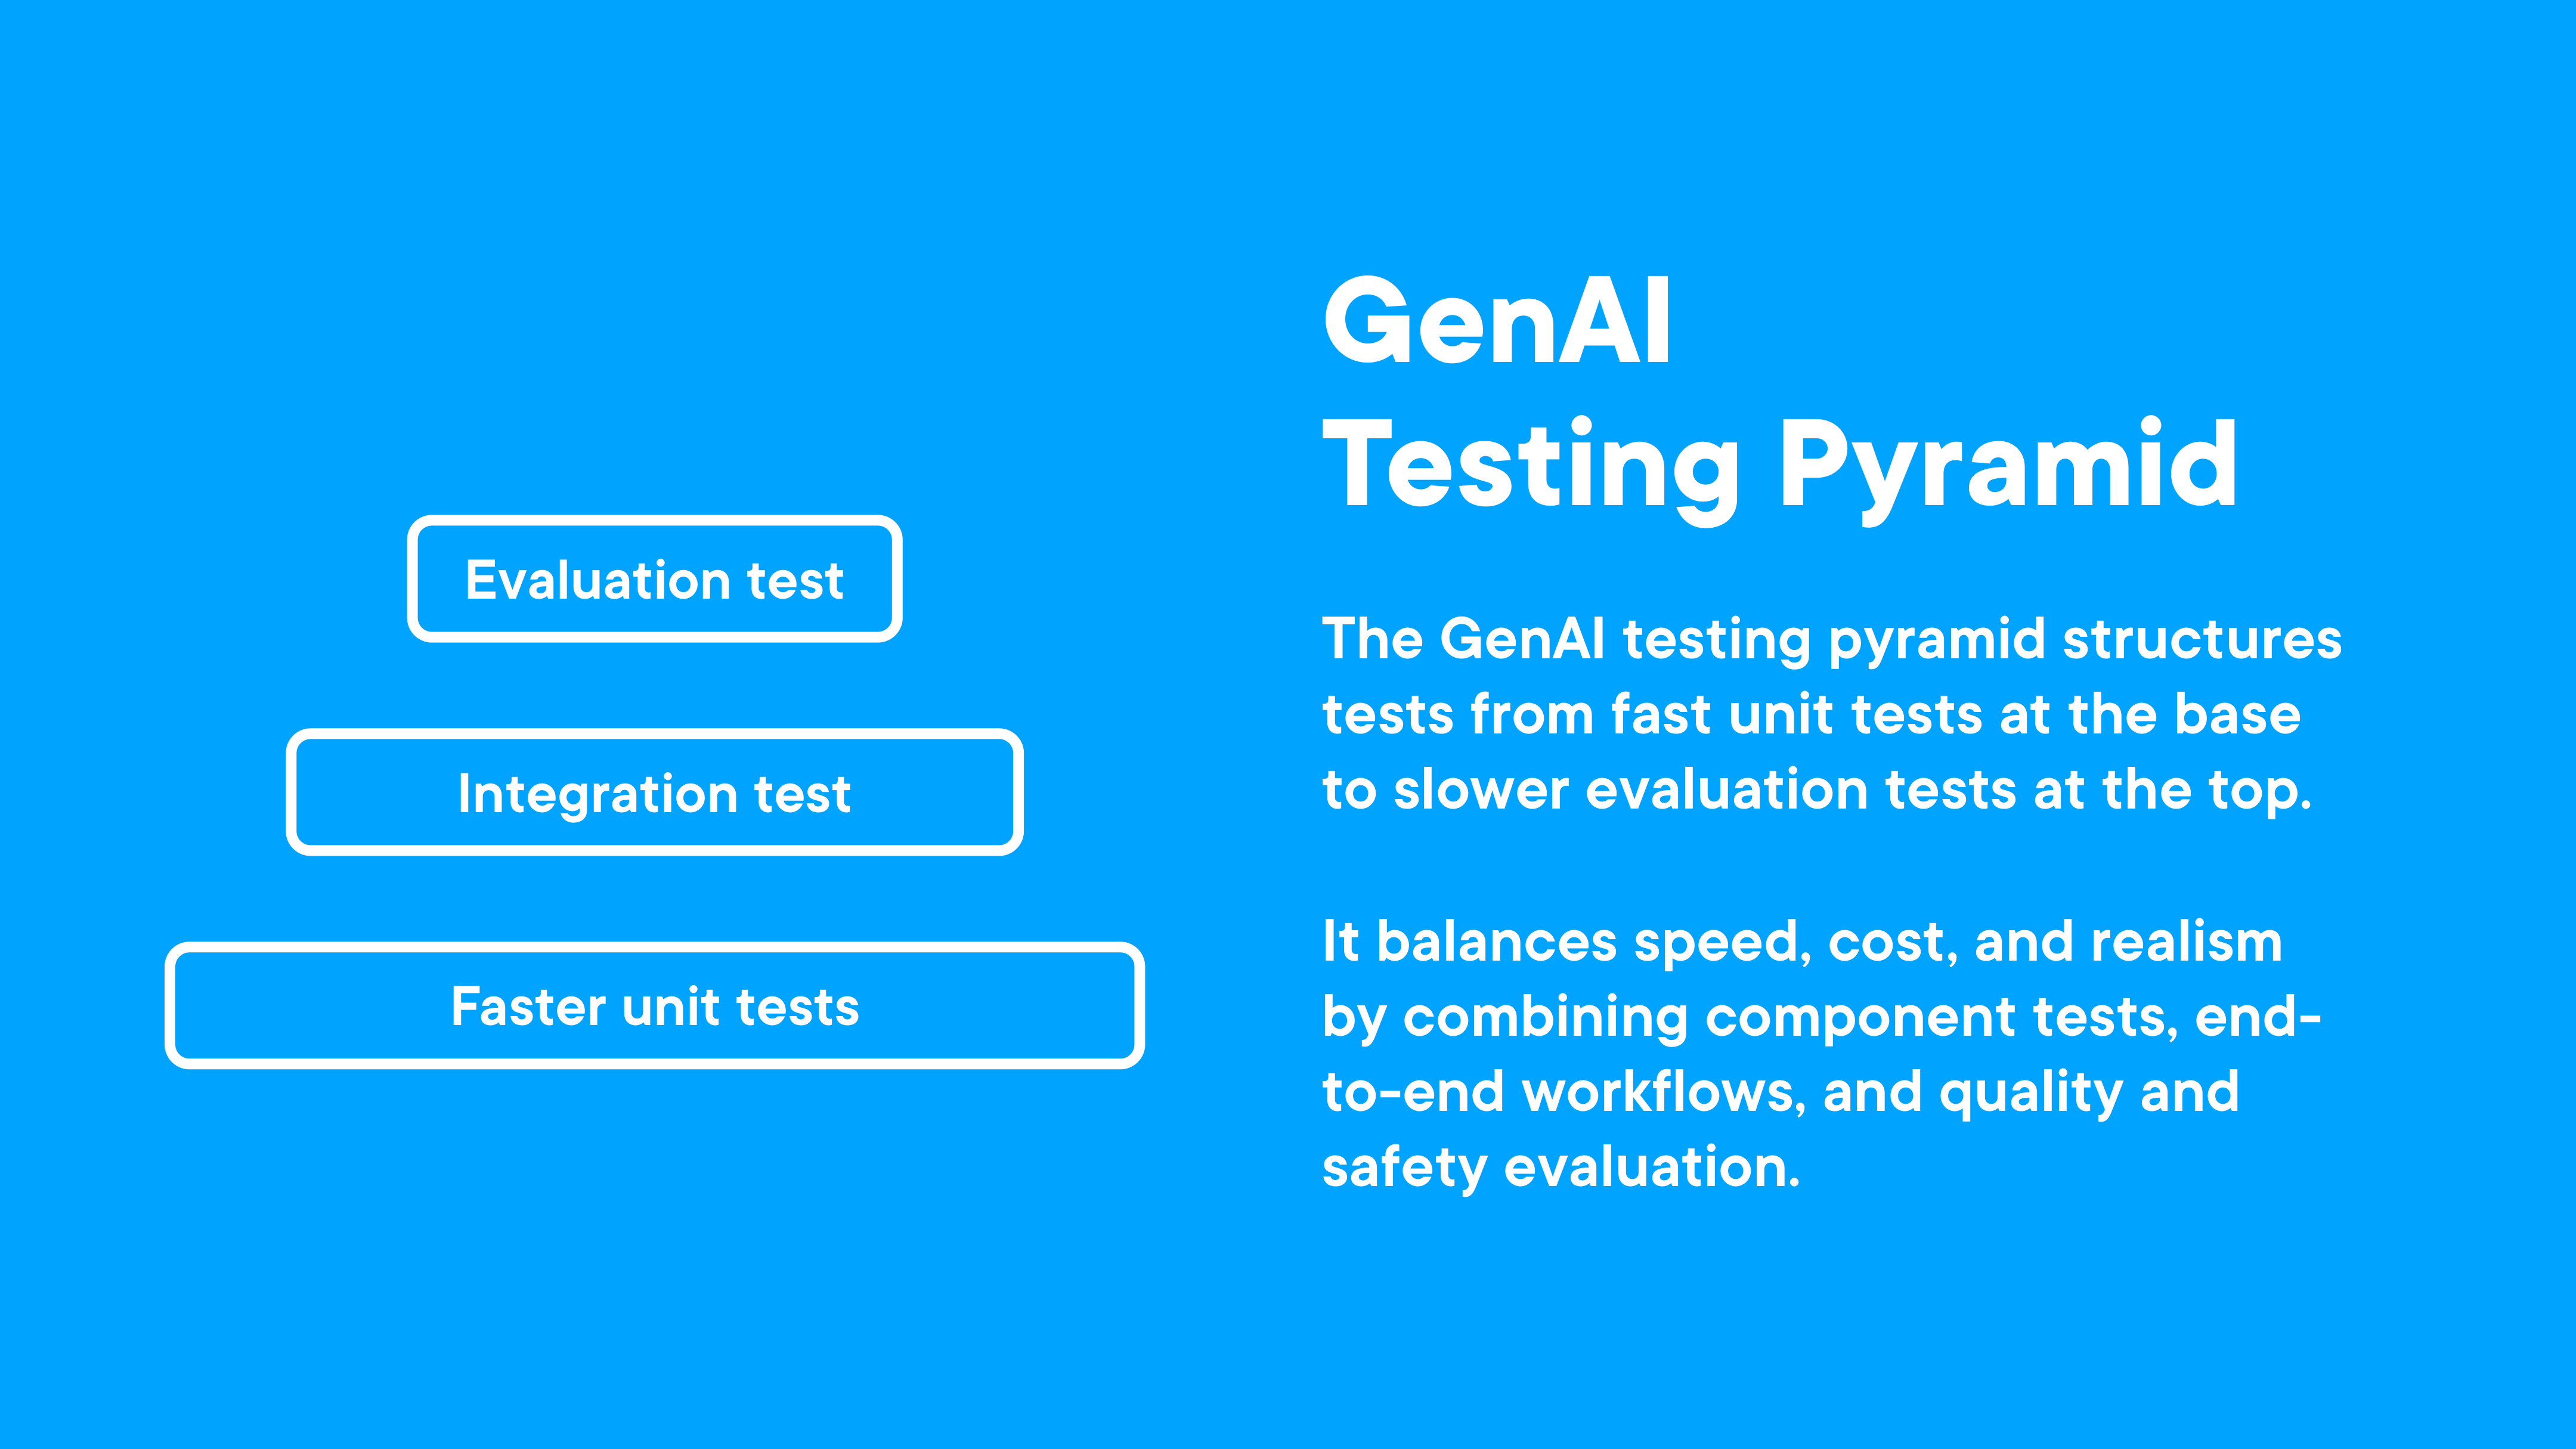

In [2]:
render_diagram(Path("assets/01-testing-pyramid.png"))


The three layers of the pyramid, from base to apex:

| Layer | Description |
|-------|-------------|
| **Unit testing** | Fast, isolated tests of individual components (prompt templates, parsers, retrievers) with mocked LLM responses |
| **Integration testing** | End-to-end workflow tests that exercise the full pipeline without mocks |
| **Evaluation testing** | Quality and safety evaluation using LLM-as-judge or golden datasets — slowest but most realistic |


#### Speed vs. Realism Trade-offs

- Fast tests enable rapid feedback during development
- Unit tests prioritize speed over realism — mocked LLMs reduce cost and variability
- Integration tests improve realism at the cost of test speed and external dependencies
- Balanced test suites combine both extremes to optimize for feedback speed _and_ production confidence


#### Quality and Safety Coverage

The evaluation layer of the pyramid specifically targets:

- Measuring output quality across dimensions
- Detecting unsafe or policy-violating behavior
- Tracking accuracy metrics over time
- Identifying safety risks before production
- Enabling continuous quality monitoring


### Unit Testing of LLM Components

Unit tests validate individual LLM components — prompt templates, output parsers, and retrievers — in isolation. By mocking the LLM response, unit tests are fast, deterministic, and free of external API dependencies.


#### Mock LLM Responses

- Enable fast, deterministic tests without external API calls
- Eliminate flakiness from non-deterministic model behavior
- Isolate application logic from LLM variability
- Simulate both valid responses and failure modes consistently
- Reduce cost and remove external service dependencies from the test suite


#### Testing Prompts and Parsers

- **Validate prompt rendering** — assert that templates produce the expected final string
- **Verify prompt completeness** — ensure all required variables are populated
- **Test parser robustness** — verify parsers handle well-formed and malformed outputs
- **Assert parser errors** — confirm that invalid responses produce the correct error path
- **Avoid live calls** — use fixture outputs to keep tests fast and isolated


#### Testing Retrieval Functions

Testing retrieval functions verifies that components responsible for fetching relevant context return correct and consistent results. It ensures retrieval logic works independently of the LLM, including filters, similarity thresholds, and edge case handling.


### Integration Testing Workflows

Integration testing ensures that prompts, models, tools, and data work together safely and reliably across real workflows — preventing hidden regressions by validating intelligence in context, not just isolated functions.


#### What Makes GenAI Integration Testing Different?

| Traditional systems | GenAI systems |
|---------------------|---------------|
| Deterministic outputs | Probabilistic outputs |
| Fixed APIs | Prompt + model behavior |
| Schema-based validation | Semantic validation |
| Mock-heavy | Real data and model calls preferred |
| Pass/fail | Score- and threshold-based |


#### Integration Testing Workflow

1. Define end-to-end scenarios covering the most important user journeys
2. Fix test determinism where possible (seed temperature, fix retrieval corpus)
3. Execute the full pipeline without mocks
4. Evaluate using multi-dimensional metrics
5. Apply automated evaluation plus human-in-the-loop review for high-risk cases

**Core components under integration test:**
- Prompt layer — template rendering and injection
- Model layer — response generation under real conditions
- Context and retrieval — document fetch and context injection
- Tool/agent layer — tool selection and execution
- Application logic — downstream processing and error handling


#### Multi-Agent Interactions and Tool Calling

Integration tests for agentic systems must verify:

- **Workflow verification** — the correct sequence of steps is executed
- **End-to-end execution** — the full pipeline runs without dropping steps
- **Multi-agent coordination** — agents hand off context correctly
- **Context exchange** — relevant state is passed between agents
- **Tool calling** — tools are invoked with correct arguments
- **Deterministic testing** — results are reproducible enough to assert against


#### End-to-End RAG Test

1. Validate the full retrieval-augmented generation workflow
2. Use deterministic settings (temperature=0, fixed corpus) for reproducible results
3. Verify correct document retrieval and context injection
4. Assert end-to-end output quality against golden responses
5. Catch integration failures across the retriever, prompt layer, and model


#### Common Failure Modes Caught by Integration Tests

- **Synthesis errors** — model fails to combine retrieved context coherently
- **Tool misuse** — agent calls a tool with wrong arguments or at the wrong step
- **Contextual hallucinations** — model invents facts not present in retrieved context
- **Response imbalance** — outputs skewed in length, tone, or coverage
- **Prompt latency** — pipeline takes too long due to retrieval or chaining overhead
- **Hidden failures** — no error raised, but output is silently wrong


#### Best Practices

- Treat prompts as versioned code — changes go through review and testing
- Maintain a golden scenario suite and run it on every change
- Track quality metrics alongside cost to expose quality/cost regressions together
- Log everything — inputs, outputs, and metadata — for post-hoc debugging
- Re-run tests periodically even with no code changes (model behavior can drift)


### Property-Based Testing for GenAI

Property-based testing validates system behavior by checking that defined invariants hold across a wide range of automatically generated inputs. It is especially effective for GenAI systems where the input space is large and unpredictable.


#### Defining Invariants

- Identify properties that must always hold true (e.g., output length ≤ 20 words, no PII in response)
- Focus on safety, structure, and behavioral guarantees rather than exact phrasing
- Avoid checking for specific text or wording — test behavior, not content
- Ensure invariants are testable and measurable programmatically
- Align invariants with production requirements and known risk areas


#### Auto-Generating Inputs

- Use property-based testing frameworks (e.g., Hypothesis) to automatically explore input spaces
- Vary input structure, length, and content to expose hidden assumptions
- Include both valid and invalid inputs to test robustness
- Control randomness with fixed seeds for deterministic CI runs
- Automatically discover edge cases that expose failure modes in GenAI systems


### Demo: GenAI Tests

This demo tests a GenAI-powered text summarization function using three test levels:

| Test type | What it checks | Purpose |
|-----------|---------------|---------|
| **Unit test** | Output length ≤ 20 words | Prevents downstream field overflow |
| **Integration test** | Output is a non-empty string | Guarantees record completeness |
| **CI gate** | All tests pass before deploy | Blocks silent regressions reaching production |

See [`03/demos.ipynb`](03/demos.ipynb) for the full notebook.


---
## Module 04: Drift Detection and Model Monitoring

_Covers types of drift in GenAI systems, drift detection techniques, monitoring dashboards, canary testing, gradual rollouts, and experiment tracking with MLflow._


### Types of Drift in GenAI Systems

Drift refers to gradual changes in system behavior over time that degrade quality, safety, or reliability without triggering obvious errors.


#### Input Distribution Drift

Occurs when the statistical or semantic properties of input data change over time. Common causes:

- Evolving user behavior and prompt patterns
- Prompt template updates
- Upstream data source changes
- Seasonal or domain-specific shifts in vocabulary and intent


#### Output Quality Drift

Refers to the gradual degradation of model response accuracy, relevance, or safety under real-world usage conditions. The three main dimensions that drift:

- **Accuracy** — factual correctness degrades as the world changes or context shifts
- **Relevance** — responses become less aligned with user intent over time
- **Safety** — model begins producing responses that were previously filtered or refused


#### Retrieval and System Drift

Retrieval quality drift is the gradual change in how embeddings, indexes, or tools retrieve and supply context to a GenAI system, leading to different outputs for the same input over time.

| Drift type | Description |
|------------|-------------|
| **Embedding drift** | Embedding model updated; existing vectors no longer comparable |
| **Index drift** | Documents added or removed; retrieval results shift |
| **Tool drift** | External tools change their API, behavior, or output format |


### Drift Detection Systems

Drift detection systems continuously monitor inputs, outputs, and system behavior to identify meaningful changes that may degrade model performance or reliability.

**Detection workflow:**

1. Establish statistical baselines from historical inputs and outputs
2. Monitor input distribution shifts and frequency changes
3. Track prompt length, token counts, language, and embedding distances
4. Measure output length, confidence, and content category distributions
5. Compare distributions using statistical distance metrics (KL divergence, Wasserstein distance)
6. Apply thresholds to detect statistically significant drift


#### Flagging Anomalies

The anomaly detection pipeline follows five stages:

1. **Baseline establishment** — compute reference distributions from stable historical data
2. **Statistical comparison** — measure distance between current and baseline distributions
3. **Threshold detection** — flag when distance exceeds configured thresholds
4. **Trend analysis** — distinguish short-term noise from sustained drift
5. **Automated alerts** — route alerts to the right teams with relevant context


#### Triggering Alerts

- Define alert thresholds based on statistically significant deviations, not arbitrary values
- Trigger alerts for _sustained_ drift rather than single noisy events
- Route alerts to the right channels or incident management systems
- Classify alerts to distinguish informational signals from critical failures
- Include metadata in alerts: model version, prompt type, time window


### Monitoring Dashboards

Monitoring dashboards provide real-time visibility into model health, performance, and cost across production GenAI systems. They enable early detection of quality, safety, and reliability issues before users are impacted.

**Key health metrics to display:**

- Error rates
- Latency percentiles (p50, p95, p99)
- Cost per request
- Output quality signals
- Safety and policy violations
- Retrieval quality metrics


#### Monitoring Metrics over Time

- Time-series tracking of all key metrics
- Baseline establishment for each metric to contextualize current values
- Drift detection signals surfaced directly on charts
- Seasonality and usage pattern overlays
- Configurable alert thresholds per metric
- Long-term system health trending for capacity and quality planning


#### Comparing Performance across Versions

- Compare error rates, latency, cost, and quality across model releases
- Evaluate the impact of prompt updates and system parameter changes
- Contrast key health metrics between experimental and stable versions
- Identify performance drops or safety regressions after deployments
- Use past baselines to contextualize current performance readings


### Canary Testing and Rollouts

Canary testing and gradual rollouts are deployment strategies that reduce risk by controlling traffic exposure to new model or prompt versions.


#### Canary Testing

A deployment strategy where a new model or prompt version is exposed to a small subset of traffic. Performance and quality metrics are compared against the baseline before rolling out to all users.



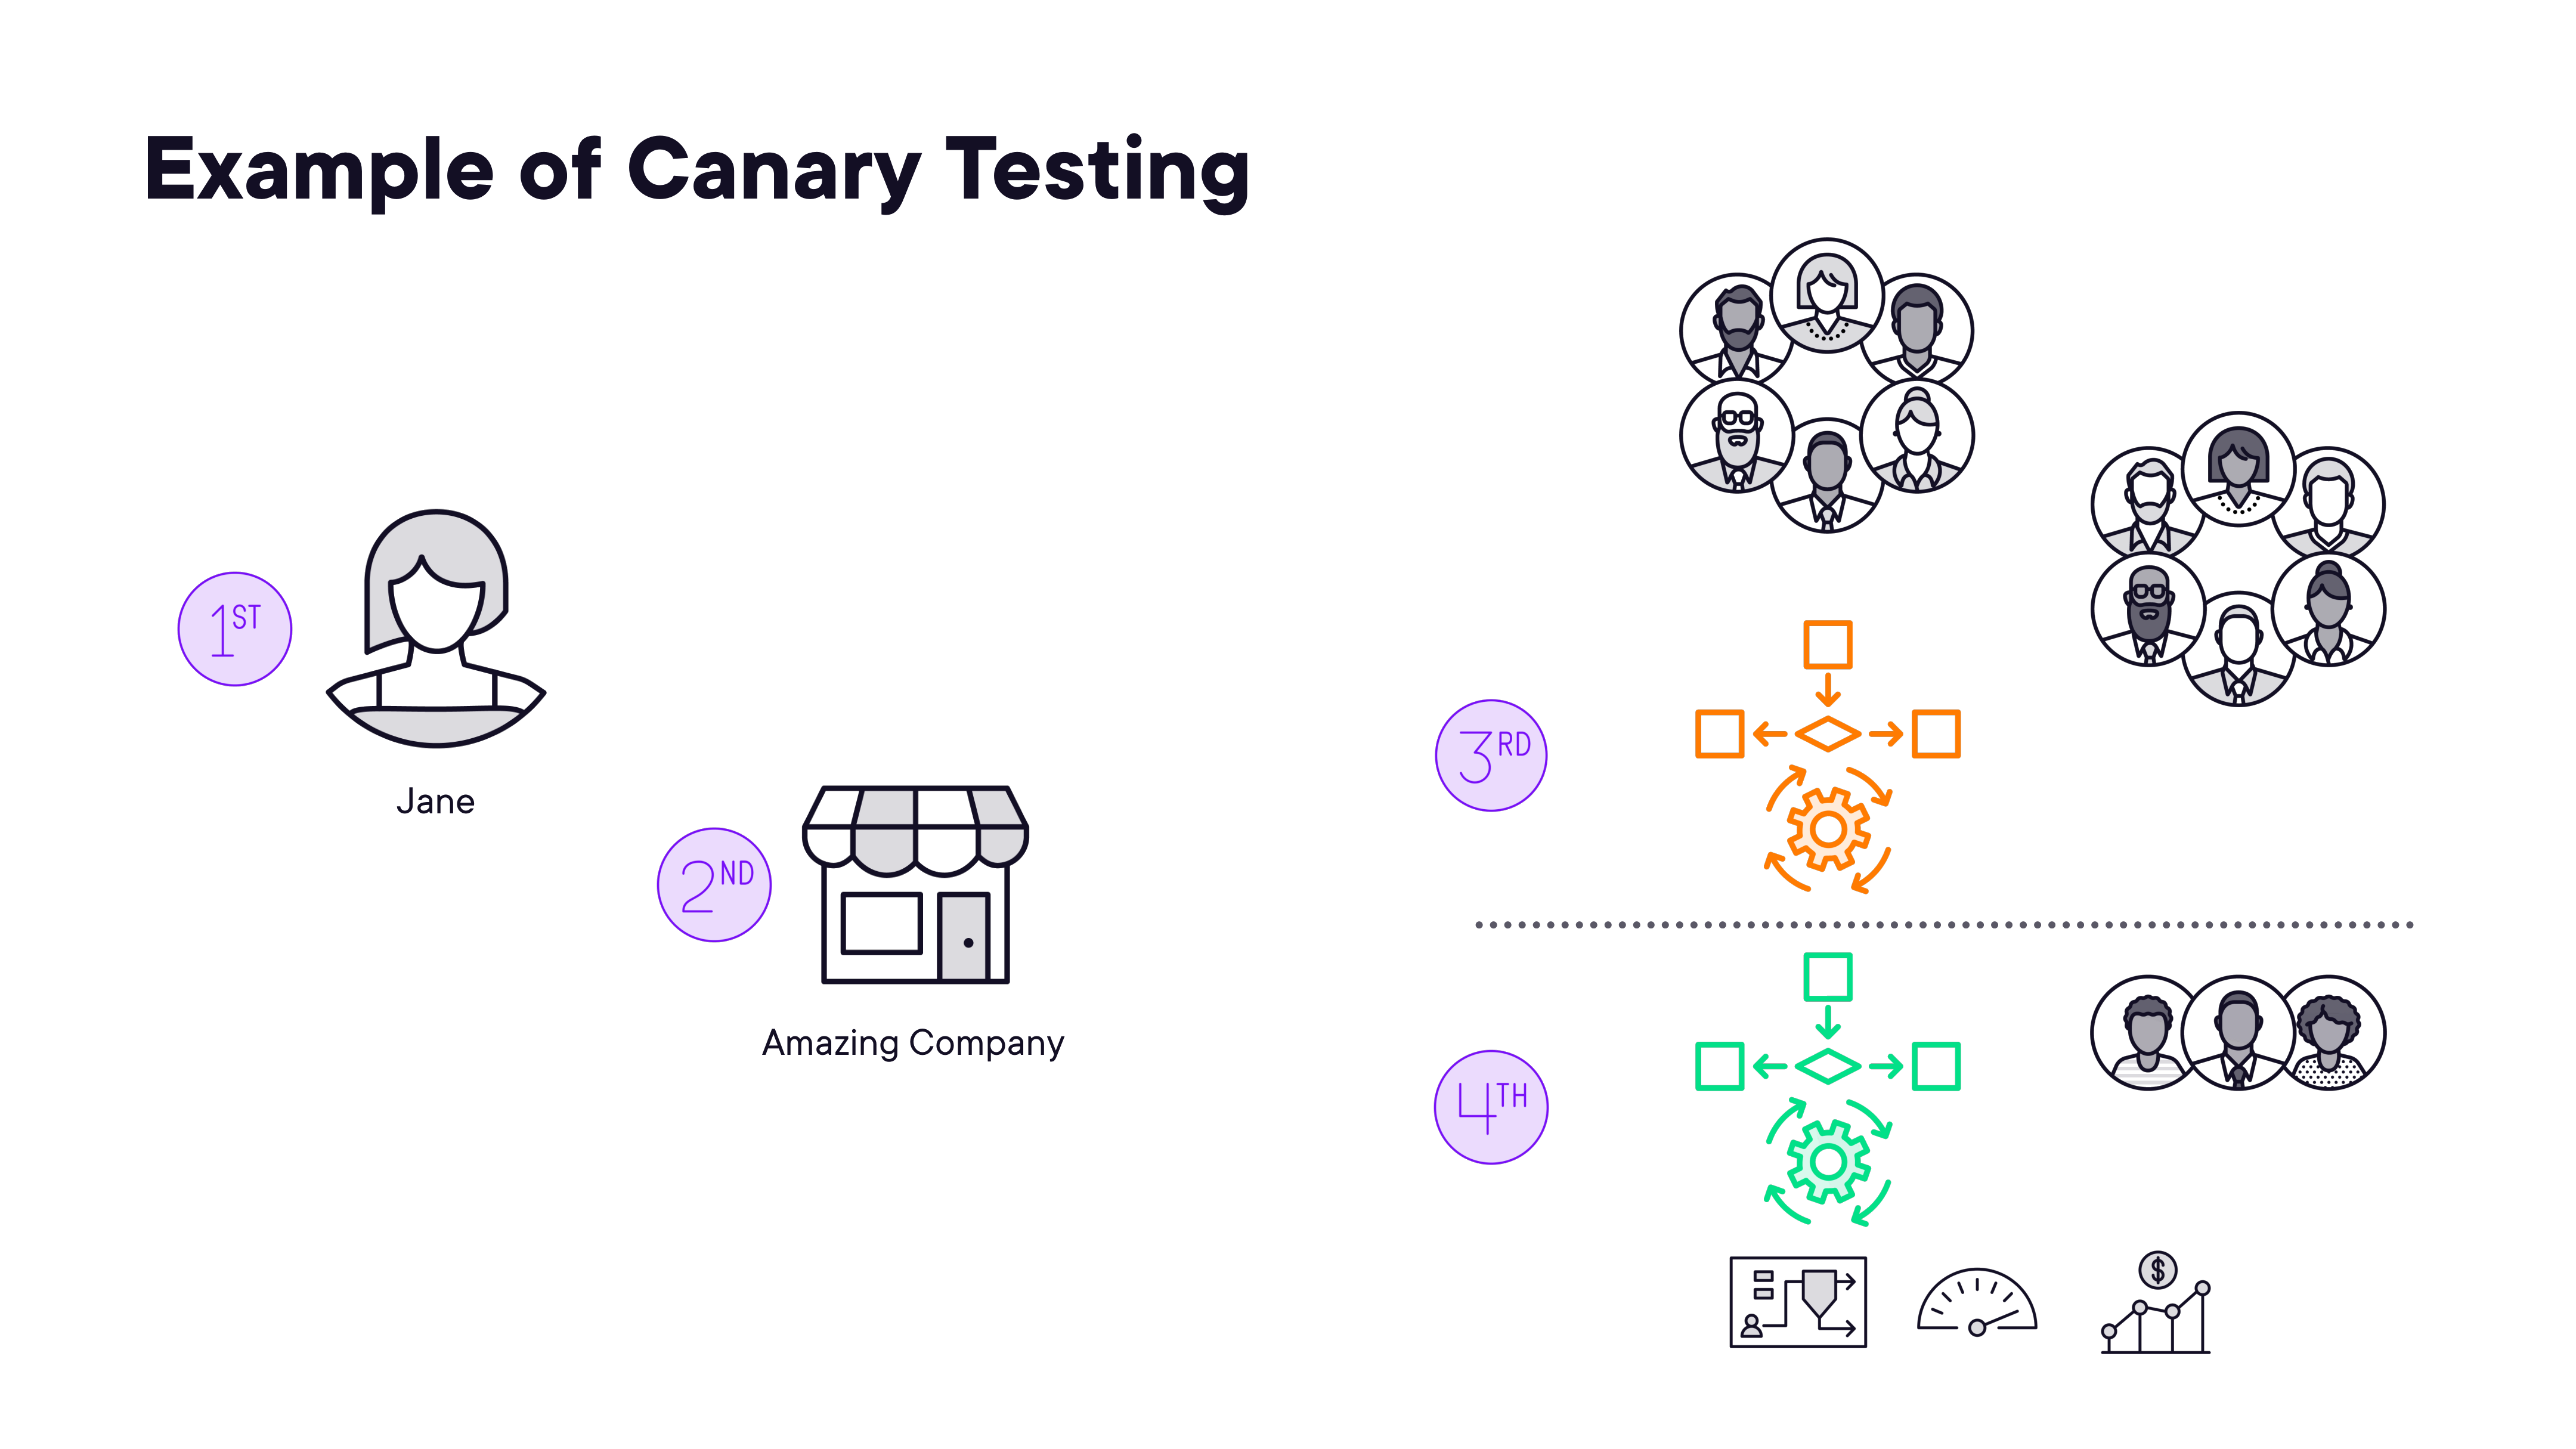

In [3]:
render_diagram(Path("assets/02-canary-testing.png"))


#### Other Deployment Testing Strategies

| Strategy | Description |
|----------|-------------|
| **Shadow testing** | New version processes requests in parallel without serving responses; results compared offline |
| **A/B testing** | Traffic split between two versions; metrics compared statistically |
| **Offline testing** | Evaluation on historical request logs before any live traffic |
| **Simulation testing** | Synthetic traffic used to test behavior under controlled conditions |
| **Regression testing** | Golden dataset re-evaluated to detect behavioral changes |


#### Gradual Rollouts

Gradual rollouts release a new model or prompt to production in small traffic increments over time. Metrics are monitored at each stage to detect issues before full deployment.

**Setup steps:**
1. Define baseline and candidate versions with full configuration snapshots
2. Route a small percentage of traffic (e.g., 5%) to the new version
3. Increase traffic in controlled stages as metrics remain healthy
4. Monitor metrics continuously and automate rollback on threshold breaches


### Experiment Tracking and Rollback

Experiment tracking records the exact configuration of each model run so results can be reproduced, compared, and rolled back.


#### Experiment Tracking Tools

| Tool | Notes |
|------|-------|
| **MLflow** | Open-source; experiment tracking, model registry, deployment |
| **Weights & Biases** | Rich visualizations; popular in research |
| **Neptune.ai** | Metadata store optimized for ML experiments |
| **ClearML** | End-to-end MLOps platform |
| **Comet** | Experiment comparison and model production monitoring |
| **DVC** | Data and model versioning via Git-based workflows |


#### Common Experimental Configurations to Track

An experimental configuration is the complete set of parameters defining a specific run — capturing what was changed so results can be compared reproducibly:

- **Model version** — model name, provider, and version tag
- **Prompt templates** — exact template text and version
- **Generation parameters** — temperature, top-p, max tokens, stop sequences
- **Retrieval settings** — embedding model, similarity threshold, top-k
- **Tool configuration** — which tools are enabled and their parameters
- **Safety guardrails** — active filters and their thresholds


#### Rollback Decisions

Trigger a rollback when any of the following are observed:

- Degraded accuracy, relevance, or user satisfaction scores
- Increased error rates, latency, or cost beyond acceptable thresholds
- Safety, compliance, or policy violations
- Worse performance than the baseline or best recorded run
- Failed canary or gradual rollout checks


### Demo: Experiment Tracking

This demo uses MLflow to compare two LLM configurations (temperature 0.0 vs. 0.7) on the same prompt. It logs model parameters, latency, output length, and success status — then uses `mlflow.search_runs` to identify the best configuration by success rate and latency.

| What to log | MLflow API | Why it matters |
|-------------|-----------|----------------|
| Model & temperature | `mlflow.log_param` | Reproduces exact conditions of each run |
| Latency | `mlflow.log_metric` | Identifies which config responds faster |
| Output length | `mlflow.log_metric` | Flags unexpectedly short or verbose responses |
| Best run selection | `mlflow.search_runs` | Picks config with highest success and lowest latency |

See [`04/demos.ipynb`](04/demos.ipynb) for the full notebook.
